In [1]:
#packages uploaded for the code
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
# euler step definition 
def euler_step(f, y, t, dt):
    # returns the next value of the varibles
    return y + dt * f(t, y)

# runge-kutta step definition
def rk4_step(f, y, t, dt):
    # fixed time-step
    k1 = f(t, y)
    k2 = f(t + dt/2, y + dt*k1/2)
    k3 = f(t + dt/2, y + dt*k2/2)
    k4 = f(t + dt, y + dt*k3)
    # returns approximent y value
    return y + dt * (k1 + 2*k2 + 2*k3 + k4) / 6

# leadfrog step function
def leapfrog_step(r, v, t, dt, accel):
    v_half = v + accel(t, r) * (dt / 2)
    r_next = r + v_half * dt
    v_next = v_half + accel(t + dt, r_next) * (dt / 2)
    # returns the next approximent state values 
    return r_next, v_next

In [3]:
# defines the system as ODE's
def ho_f(t, y):
    # y = [x, dx/dt]
    return np.array([y[1], -y[0]])

# computes acceleration for leap frog intergration
def ho_accel(t, r):
    # Leapfrog uses direct acceleration 
    return -r

# value definitions
t_max = 30.0
stepsizes = [1.0, 0.3, 0.1, 0.03, 0.01]
exact_val = np.cos(t_max)

# values calculated for each intergration type
print(f"Exact Analytical Solution at t=30: {exact_val:.6f}\n")
print(f"{'Step (dt)':<10}{'Euler Error':<15}{'RK4 Error':<15}{'Leapfrog Error':<15}")
print("-" * 55)

# lists for error values
errors = {'Euler': [], 'RK4': [], 'Leapfrog': []}

# calculation for the different intergration types; looping through the various steps
for dt in stepsizes:
    # Forward Euler
    t, y = 0.0, np.array([1.0, 0.0])
    # runs loop until it hits the max time
    while t < t_max - 1e-10:
        y = euler_step(ho_f, y, t, dt)
        t += dt
    # calculates error
    err_euler = abs(y[0] - exact_val)
    errors['Euler'].append(err_euler)
    
    # RK4
    t, y = 0.0, np.array([1.0, 0.0])
    while t < t_max - 1e-10:
        y = rk4_step(ho_f, y, t, dt)
        t += dt
    err_rk4 = abs(y[0] - exact_val)
    errors['RK4'].append(err_rk4)
    
    # Leapfrog
    t, r, v = 0.0, 1.0, 0.0
    while t < t_max - 1e-10:
        r, v = leapfrog_step(r, v, t, dt, ho_accel)
        t += dt
    err_lf = abs(r - exact_val)
    errors['Leapfrog'].append(err_lf)
    
    print(f"{dt:<10}{err_euler:<15.2e}{err_rk4:<15.2e}{err_lf:<15.2e}")


Exact Analytical Solution at t=30: 0.154251

Step (dt) Euler Error    RK4 Error      Leapfrog Error 
-------------------------------------------------------
1.0       1.54e-01       1.65e-01       8.46e-01       
0.3       4.80e+01       2.01e-03       1.11e-01       
0.1       9.24e-02       2.49e-05       1.24e-02       
0.03      7.37e-02       2.01e-07       1.11e-03       
0.01      2.38e-02       2.47e-09       1.24e-04       


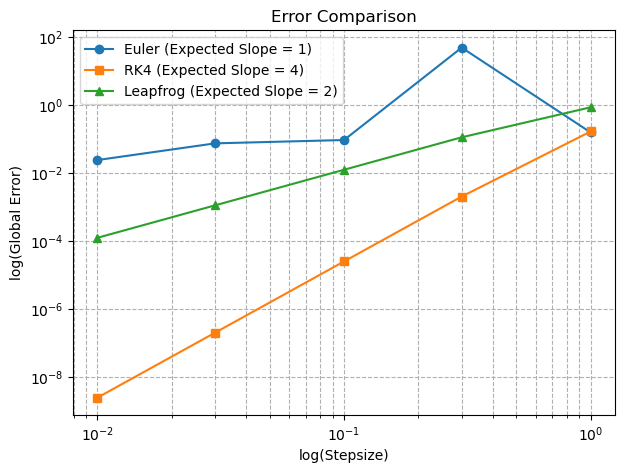

In [4]:
# creation of the graph comparing error to stepsize
plt.figure(figsize=(7, 5))
plt.loglog(stepsizes, errors['Euler'], 'o-', label='Euler (Expected Slope = 1)')
plt.loglog(stepsizes, errors['RK4'], 's-', label='RK4 (Expected Slope = 4)')
plt.loglog(stepsizes, errors['Leapfrog'], '^-', label='Leapfrog (Expected Slope = 2)')
plt.xlabel('log(Stepsize)')
plt.ylabel('log(Global Error)')
plt.title('Error Comparison')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

In [5]:
# calculates gravitational potential energy
def pot(x, y):
    return -1.0 / np.sqrt(1.0 + x**2 + y**2)

# calculates 2D gravitational acceleration
def orbit_accel(t, r):
    x, y = r[0], r[1]
    denom = (1.0 + x**2 + y**2)**1.5
    return np.array([-x / denom, -y / denom])

# returns derivatives
def orbit_f(t, state):
    x, y, vx, vy = state
    a = orbit_accel(t, [x, y])
    return np.array([vx, vy, a[0], a[1]])

# defining the step sizes to test
step_sizes = [1.0, 0.3, 0.1, 0.03, 0.01]

# dictionary to store results for each step size
results = {}

# simulation parameters to loop through
for dt in step_sizes:
    t_max_orbit = 100.0
    init_r = np.array([1.0, 0.0])
    init_v = np.array([0.0, 0.3])

        # Run Leapfrog
    t, r, v = 0.0, init_r.copy(), init_v.copy()
    # lists for history 
    lf_r_hist, lf_v_hist, lf_t_hist = [r], [v], [t]
    while t < t_max_orbit - 1e-10:
        # calculating via leapfrog
        r, v = leapfrog_step(r, v, t, dt, orbit_accel)
        t += dt
        lf_r_hist.append(r)
        lf_v_hist.append(v)
        lf_t_hist.append(t)
    # convert data to arrays
    lf_r_hist, lf_v_hist = np.array(lf_r_hist), np.array(lf_v_hist)
    
    # Run RK4
    t, state = 0.0, np.append(init_r, init_v)
    rk_state_hist, rk_t_hist = [state], [t]
    while t < t_max_orbit - 1e-10:
        state = rk4_step(orbit_f, state, t, dt)
        t += dt
        rk_state_hist.append(state)
        rk_t_hist.append(t)
    rk_state_hist = np.array(rk_state_hist)

    # calculate the energy for leapfrog and runge-kutta
    E_lf = 0.5 * (lf_v_hist[:,0]**2 + lf_v_hist[:,1]**2) + pot(lf_r_hist[:,0], lf_r_hist[:,1])
    E_rk = 0.5 * (rk_state_hist[:,2]**2 + rk_state_hist[:,3]**2) + pot(rk_state_hist[:,0], rk_state_hist[:,1])

    # save the calculated results to plot them
    results[dt] = {
        'lf_x': lf_r_hist[:, 0],
        'lf_y': lf_r_hist[:, 1],
        'rk_x': rk_state_hist[:, 0],
        'rk_y': rk_state_hist[:, 1],
        'E_lf': E_lf,
        'E_rk': E_rk,
        'lf_t': np.array(lf_t_hist),
        'rk_t': np.array(rk_t_hist)
    }

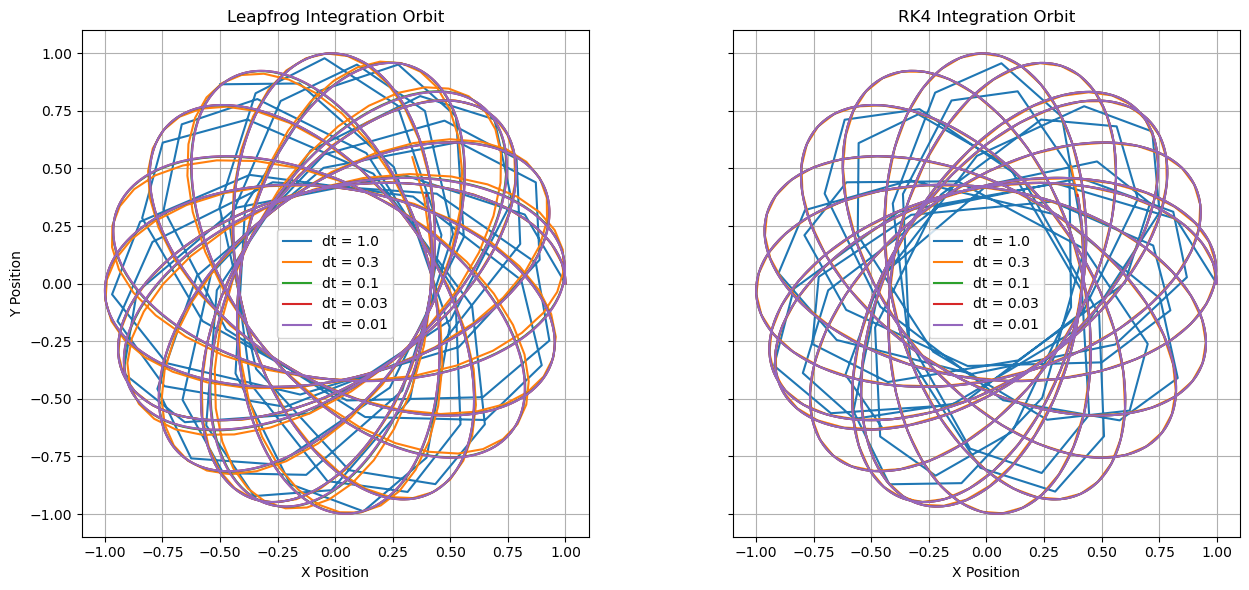

In [6]:
# plotting the trajectories
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# plot Leapfrog Results
for dt in step_sizes:
    axes[0].plot(results[dt]['lf_x'], results[dt]['lf_y'], label=f'dt = {dt}')
    axes[0].set_title('Leapfrog Integration Orbit')
    axes[0].set_xlabel('X Position')
    axes[0].set_ylabel('Y Position')
    axes[0].grid(True)
    axes[0].legend()
    axes[0].set_aspect('equal')

# plot RK4 Results
for dt in step_sizes:
    axes[1].plot(results[dt]['rk_x'], results[dt]['rk_y'], label=f'dt = {dt}')
    axes[1].set_title('RK4 Integration Orbit')
    axes[1].set_xlabel('X Position')
    axes[1].grid(True)
    axes[1].legend()
    axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()

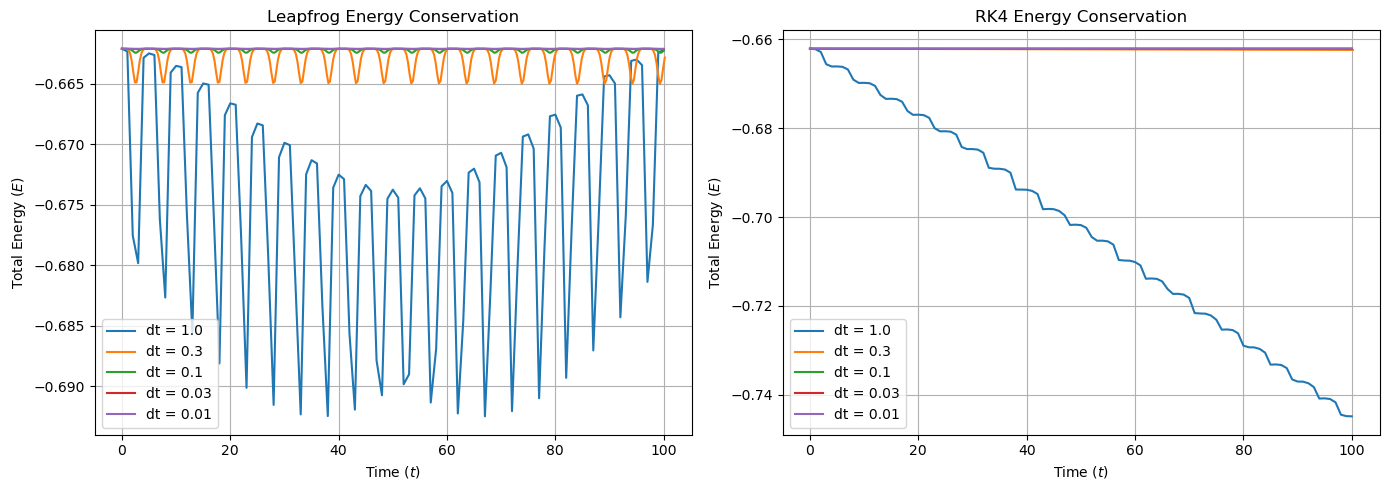

In [7]:
# create a figure with 2 subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# loop over each step size to plot the energy data
for dt, data in results.items():
    # plot Leapfrog energy vs Time
    ax1.plot(data['lf_t'], data['E_lf'], label=f'dt = {dt}')
    
    # plot RK4 energy vs Time
    ax2.plot(data['rk_t'], data['E_rk'], label=f'dt = {dt}')

# Leapfrog Plot
ax1.set_title('Leapfrog Energy Conservation')
ax1.set_xlabel('Time ($t$)')
ax1.set_ylabel('Total Energy ($E$)')
ax1.grid(True)
ax1.legend()

# RK4 Plot
ax2.set_title('RK4 Energy Conservation')
ax2.set_xlabel('Time ($t$)')
ax2.set_ylabel('Total Energy ($E$)')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()


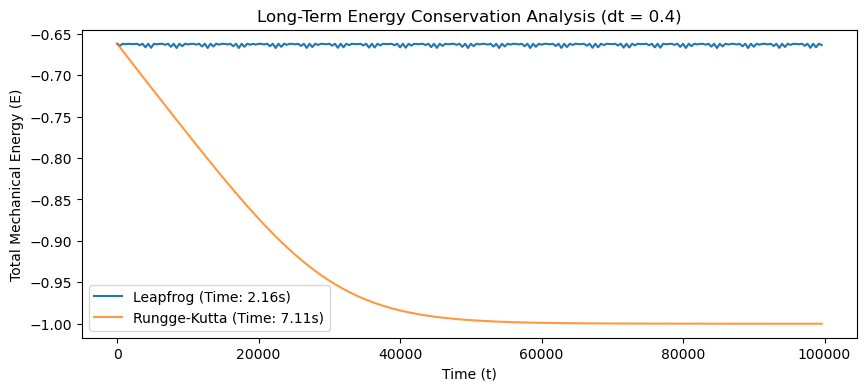

In [8]:
# define the extra long time for the situation
t_long_max = 100000.0
dt_long = 0.4

# Run leapfrog
t, r, v = 0.0, init_r.copy(), init_v.copy()
lf_times, lf_energies = [], []
start_lf = time.time()
while t < t_long_max - 1e-10:
    if int(t / dt_long) % 1000 == 0:  # subsample to conserve plotting memory
        lf_times.append(t)
        lf_energies.append(0.5 * np.dot(v, v) + pot(r[0], r[1]))
    r, v = leapfrog_step(r, v, t, dt_long, orbit_accel)
    t += dt_long
wall_lf = time.time() - start_lf

# Run rugge-kutta
t, state = 0.0, np.append(init_r, init_v)
rk_times, rk_energies = [], []
start_rk = time.time()
while t < t_long_max - 1e-10:
    if int(t / dt_long) % 1000 == 0:
        rk_times.append(t)
        rk_energies.append(0.5 * (state[2]**2 + state[3]**2) + pot(state[0], state[1]))
    state = rk4_step(orbit_f, state, t, dt_long)
    t += dt_long
wall_rk = time.time() - start_rk

# Plot energy variations over time
plt.figure(figsize=(10, 4))
plt.plot(lf_times, lf_energies, label=f'Leapfrog (Time: {wall_lf:.2f}s)')
plt.plot(rk_times, rk_energies, label=f'Rungge-Kutta (Time: {wall_rk:.2f}s)', alpha=0.8)
plt.xlabel('Time (t)')
plt.ylabel('Total Mechanical Energy (E)')
plt.title('Long-Term Energy Conservation Analysis (dt = 0.4)')
plt.legend()
plt.show()

Rungge-Kutta is four times as slow as Leapfrog, as leapfrog only requires 1 evaluation per step while rungge-kutta requires 4. Additionally, rungge-kutta accumulates errors significantly overtime unlike leapfrog, which has a low total accumulated error over a significantly large amount of time.